<a href="https://colab.research.google.com/github/Wawawa819/sms-spam-classification/blob/main/spam_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS 스팸 메시지 분류
TF-IDF로 문자를 수치화하고 분류 모델 3개를 비교해, **어떤 오류를 더 줄일지 기준을 정한 뒤** 모델을 고른다.

- 데이터: SMS Spam Collection (문자 5,572개)
- 실행: 위에서부터 한 칸씩 `Shift + Enter`
- 각 단계 끝의 **📝 메모** 칸에 결과를 직접 적어 두기 (면접 답변 재료)

## 1. 환경 준비와 데이터 불러오기

In [14]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(URL, sep="\t", header=None, names=["label", "text"])

print(df.shape)
df.head()

(5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. 데이터 살펴보기 (EDA)

label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     86.6
spam    13.4
Name: count, dtype: float64 (%)


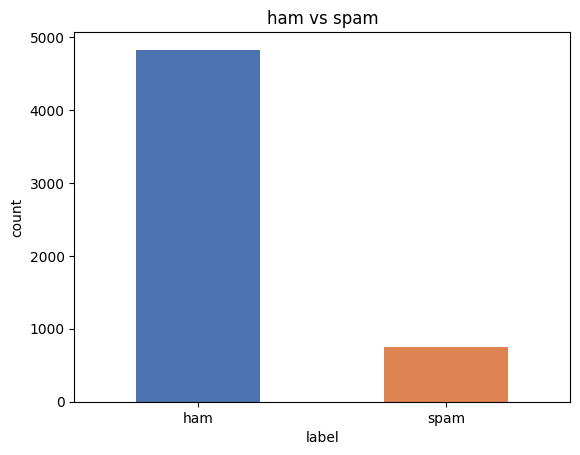

In [15]:
counts = df["label"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1), "(%)")

counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("ham vs spam")
plt.ylabel("count")
plt.xticks(rotation=0)
plt.show()

        count   mean   std   min    25%    50%    75%    max
label                                                       
ham    4825.0   71.5  58.4   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0


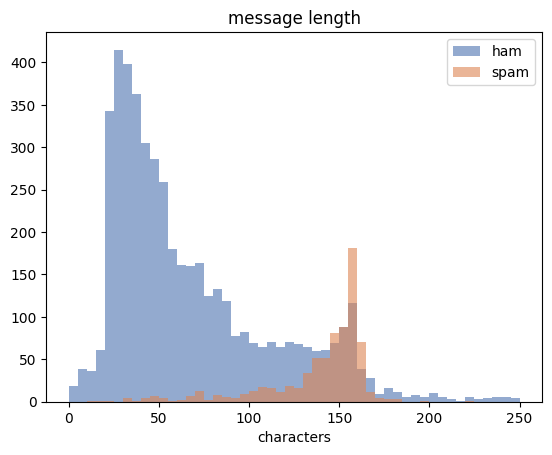

In [16]:
# 문자 길이 비교: 스팸이 더 길까?
df["length"] = df["text"].str.len()
print(df.groupby("label")["length"].describe().round(1))

for lab, color in [("ham", "#4C72B0"), ("spam", "#DD8452")]:
    plt.hist(df.loc[df.label == lab, "length"], bins=50, alpha=0.6, label=lab, color=color, range=(0, 250))
plt.xlabel("characters")
plt.legend()
plt.title("message length")
plt.show()

In [17]:
# 모든 문자를 '정상'이라고 찍기만 해도 정확도는?
baseline = (df["label"] == "ham").mean()
print(f"전부 ham으로 예측했을 때 정확도: {baseline:.1%}")

전부 ham으로 예측했을 때 정확도: 86.6%


📝 **메모**: 스팸 비율 **13.4%**, 전부 정상으로 찍어도 정확도 **86.6%** → 정확도가 높게 나와도 스팸을 하나도 못 잡는 모델일 수 있기 때문에, 정확도만으로는 성능을 판단할 수 없다.

- 스팸 문자는 평균 139자로, 정상 문자(평균 72자)보다 약 2배 길다.

## 3. 전처리

In [18]:
def clean(text):
    text = text.lower()                       # 소문자로
    text = re.sub(r"[^a-z0-9\s]", " ", text)  # 특수문자 제거
    text = re.sub(r"\s+", " ", text).strip()  # 공백 정리
    return text

df["clean"] = df["text"].apply(clean)
df["y"] = (df["label"] == "spam").astype(int)  # spam=1, ham=0

for i in [2, 5, 8]:
    print("전:", df.loc[i, "text"])
    print("후:", df.loc[i, "clean"], "\n")

전: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
후: free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry question std txt rate t c s apply 08452810075over18 s 

전: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
후: freemsg hey there darling it s been 3 week s now and no word back i d like some fun you up for it still tb ok xxx std chgs to send 1 50 to rcv 

전: WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
후: winner as a valued network customer you have been selected to receivea 900 prize reward to claim call 09061701461 claim code kl341 valid 12 hours only 



In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["y"], test_size=0.2, stratify=df["y"], random_state=42
)
# stratify: 학습/테스트 양쪽의 스팸 비율을 똑같이 유지
print("학습:", len(X_train), " 테스트:", len(X_test))
print("학습 스팸 비율:", round(y_train.mean(), 3), " 테스트 스팸 비율:", round(y_test.mean(), 3))

학습: 4457  테스트: 1115
학습 스팸 비율: 0.134  테스트 스팸 비율: 0.134


## 4. TF-IDF 수치화

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(stop_words="english")   # the, is 같은 불용어 제거
X_train_v = vec.fit_transform(X_train)        # 학습 데이터로만 단어장 생성(fit)
X_test_v = vec.transform(X_test)              # 테스트는 변환만 (정보 누출 방지)

print("단어 수(벡터 차원):", X_train_v.shape[1])

단어 수(벡터 차원): 7399


In [21]:
# 스팸 문자에서 평균 TF-IDF 점수가 높은 단어 상위 10개
words = np.array(vec.get_feature_names_out())
spam_mean = np.asarray(X_train_v[(y_train == 1).values].mean(axis=0)).ravel()
ham_mean = np.asarray(X_train_v[(y_train == 0).values].mean(axis=0)).ravel()
print("스팸 상위:", list(words[spam_mean.argsort()[::-1][:10]]))
print("정상 상위:", list(words[ham_mean.argsort()[::-1][:10]]))

스팸 상위: ['free', 'txt', 'claim', 'mobile', 'stop', 'text', 'ur', 'reply', 'www', 'prize']
정상 상위: ['ok', 'll', 'come', 'gt', 'lt', 'just', 'good', 'got', 'sorry', 'home']


📝 **메모**: 스팸에서 눈에 띄는 단어: **free, txt, claim, mobile, stop, reply, www, prize**. 무료·당첨·답장 유도처럼 행동을 요구하는 단어가 많다. 정상 문자는 ok, come, sorry, home 같은 일상 대화 단어가 많다.

## 5. 모델 3개 학습

In [22]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}
preds = {}
for name, m in models.items():
    m.fit(X_train_v, y_train)
    preds[name] = m.predict(X_test_v)
print("학습 완료")

학습 완료


## 6. 평가

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

rows = []
for name, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({
        "model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "놓친 스팸(FN)": fn,
        "막힌 정상(FP)": fp,
    })
result = pd.DataFrame(rows).set_index("model").round(3)
result

,Accuracy,Precision,Recall,F1,놓친 스팸(FN),막힌 정상(FP)
model,,,,,,
Naive Bayes,0.970,1.000,0.779,0.875,33,0
Logistic Regression,0.968,1.000,0.758,0.863,36,0
Linear SVM,0.984,0.992,0.886,0.936,17,1


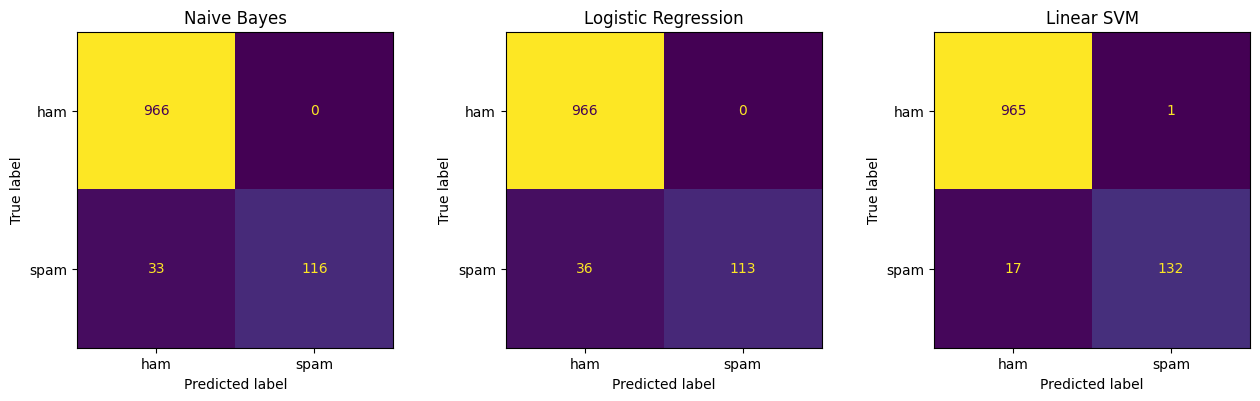

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=["ham", "spam"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

📝 **메모**: 정확도 차이는 **96.8~98.4%로 1.6%p**인데, 놓친 스팸 수는 **17개부터 36개까지 2배 넘게** 차이 → 정확도가 비슷해도 실제로 스팸을 걸러내는 능력(Recall)은 크게 다르다.

- **Precision(정밀도)**: 스팸이라고 막은 것 중 진짜 스팸 비율 → 낮으면 정상 문자가 막힘
- **Recall(재현율)**: 진짜 스팸 중 잡아낸 비율 → 낮으면 스팸이 그대로 들어옴

## 7. 오분류 분석과 모델 선택

In [25]:
def show_errors(name, n=10):
    p = preds[name]
    test = pd.DataFrame({"text": df.loc[X_test.index, "text"], "y": y_test, "pred": p})
    fn = test[(test.y == 1) & (test.pred == 0)]
    fp = test[(test.y == 0) & (test.pred == 1)]
    print(f"[{name}] 놓친 스팸 {len(fn)}개 / 막힌 정상 {len(fp)}개\n")
    print("--- 놓친 스팸 ---")
    for t in fn["text"].head(n):
        print("-", t)
    print("\n--- 스팸으로 잘못 막힌 정상 문자 ---")
    for t in fp["text"].head(n):
        print("-", t)

show_errors("Naive Bayes")

[Naive Bayes] 놓친 스팸 33개 / 막힌 정상 0개

--- 놓친 스팸 ---
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
- Dear Voucher Holder 2 claim your 1st class airport lounge passes when using Your holiday voucher call 08704439680. When booking quote 1st class x 2
- Talk sexy!! Make new friends or fall in love in the worlds most discreet text dating service. Just text VIP to 83110 and see who you could meet.
- sexy sexy cum and text me im wet and warm and ready for some porn! u up for some fun? THIS MSG IS FREE RECD MSGS 150P INC VAT 2 CANCEL TEXT STOP
- Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx Calls£1/minMobsmoreLKPOBOX177HP51FL
- ringtoneking 84484
- Sorry I missed your call let's talk when you have the time. I'm on 07090201529
- Rock yr chik. Get 100's of filthy films &XXX pics on yr phone now. rply FILTH to 69669. Sa

In [26]:
show_errors("Linear SVM")

[Linear SVM] 놓친 스팸 17개 / 막힌 정상 1개

--- 놓친 스팸 ---
- Dear Voucher Holder 2 claim your 1st class airport lounge passes when using Your holiday voucher call 08704439680. When booking quote 1st class x 2
- Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx Calls£1/minMobsmoreLKPOBOX177HP51FL
- ringtoneking 84484
- Sorry I missed your call let's talk when you have the time. I'm on 07090201529
- Latest News! Police station toilet stolen, cops have nothing to go on!
- Romantic Paris. 2 nights, 2 flights from £79 Book now 4 next year. Call 08704439680Ts&Cs apply.
- Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Calls£1/minmoremobsEMSPOBox45PO139WA
- More people are dogging in your area now. Call 09090204448 and join like minded guys. Why not arrange 1 yourself. There's 1 this evening. A£1.50 minAPN LS278BB
- For sale - arsenal dartboard. Good condition but no d

📝 **메모**
- **놓친 스팸의 공통점**
    - free, claim 같은 스팸 단어 없이 일상 대화처럼 쓴 문자 (예: "Sorry I missed your call… I'm on 0709…")
    - "ringtoneking 84484"처럼 아주 짧은 문자
    - drvgs, wiv처럼 일부러 틀린 철자나 띄어쓰기 없이 붙은 단어 → 학습한 단어장에 없어서 점수가 안 잡힘
    - 전화번호가 있지만 번호가 문자마다 달라서 하나의 특징으로 학습되지 않음
- **막힌 정상 문자의 공통점**: SVM이 막은 1개("K..u also dont msg or reply to his msg..")는 스팸에 자주 나오는 msg, reply가 들어간 짧은 문자
- **더 줄여야 하는 오류**: **정상 문자 막기**. 스팸은 한 통 들어와도 지우면 되지만, 정상 문자가 막히면 중요한 연락을 놓친다. 그래서 Precision을 거의 1로 유지하면서 Recall이 가장 높은 모델을 고른다.
- **선택한 모델**: **Linear SVM**. 정상 문자를 막은 건 테스트 1,115개 중 1개(Precision 0.992)로 거의 그대로이면서, 놓친 스팸은 33~36개에서 17개로 절반 이하로 줄었다(Recall 0.886).
- **개선 아이디어**: 전화번호를 하나의 특징(예: `PHONE` 토큰)으로 바꾸고, 글자 단위 n-gram으로 틀린 철자도 잡기